# B2B SaaS Revenue & Customer Intelligence
Intermediate portfolio | Synthetic data | USD

**Business question:** Which plans and markets drive recurring revenue, and which customer groups show higher historical churn? Evaluate billing and support, then compare exploratory churn classifiers. Each stage has separate executable cells.

## 1. Import libraries and locate data

In [1]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay

In [2]:
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
raw = ROOT / 'data/raw'

## 2. Load each dataset

In [3]:
a = pd.read_csv(raw / 'accounts.csv')

In [4]:
s = pd.read_csv(raw / 'subscriptions.csv')

In [5]:
i = pd.read_csv(raw / 'invoices.csv')

In [6]:
t = pd.read_csv(raw / 'support_tickets.csv')

In [7]:
u = pd.read_csv(raw / 'users.csv')

## 3. Inspect shape, sample, info and describe
Identifiers are labels, not quantitative business measurements. User names and emails are excluded from displayed samples.

### Accounts

In [8]:
print(a.shape)

(1200, 7)


In [9]:
display(a.drop(columns=['company_name','full_name','email'], errors='ignore').head())

,account_id,industry,country,employee_count,signup_date,plan
0,1,Software,Brazil,48,2023-01-03 17:06:49,Growth
1,2,Software,Netherlands,4,2023-01-04 06:54:39,Starter
2,3,Retail,United Kingdom,6,2023-01-09 20:36:29,Starter
3,4,Financial Services,Brazil,16,2023-01-10 23:28:05,Growth
4,5,Manufacturing,United Kingdom,51,2023-01-17 09:06:19,Business


In [10]:
a.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   account_id      1200 non-null   int64 
 1   company_name    1200 non-null   object
 2   industry        1200 non-null   object
 3   country         1200 non-null   object
 4   employee_count  1200 non-null   int64 
 5   signup_date     1200 non-null   object
 6   plan            1200 non-null   object
dtypes: int64(2), object(5)
memory usage: 65.8+ KB


In [11]:
display(a.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
account_id,1200.0,NaN,NaN,NaN,600.5,346.554469,1.0,300.75,600.5,900.25,1200.0
company_name,1200,1200,Oakleaf Labs,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
industry,1200,7,Software,320,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,1200,10,United States,422,NaN,NaN,NaN,NaN,NaN,NaN,NaN
employee_count,1200.0,NaN,NaN,NaN,50.975,83.048913,3.0,12.0,27.0,60.0,1360.0
signup_date,1200,1200,2023-01-03 17:06:49,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
plan,1200,4,Starter,466,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Subscriptions

In [12]:
print(s.shape)

(1200, 7)


In [13]:
display(s.drop(columns=['company_name','full_name','email'], errors='ignore').head())

,subscription_id,account_id,seats,status,mrr,started_on,ended_on
0,500001,1,40,active,960,2023-01-03 17:06:49,NaN
1,500002,2,4,churned,48,2023-01-04 06:54:39,2025-10-04 20:35:52
2,500003,3,6,active,72,2023-01-09 20:36:29,NaN
3,500004,4,15,active,360,2023-01-10 23:28:05,NaN
4,500005,5,51,active,2244,2023-01-17 09:06:19,NaN


In [14]:
s.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   subscription_id  1200 non-null   int64 
 1   account_id       1200 non-null   int64 
 2   seats            1200 non-null   int64 
 3   status           1200 non-null   object
 4   mrr              1200 non-null   int64 
 5   started_on       1200 non-null   object
 6   ended_on         293 non-null    object
dtypes: int64(4), object(3)
memory usage: 65.8+ KB


In [15]:
display(s.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
subscription_id,1200.0,NaN,NaN,NaN,500600.5,346.554469,500001.0,500300.75,500600.5,500900.25,501200.0
account_id,1200.0,NaN,NaN,NaN,600.5,346.554469,1.0,300.75,600.5,900.25,1200.0
seats,1200.0,NaN,NaN,NaN,29.4325,48.828157,1.0,8.0,13.0,36.0,851.0
status,1200,4,active,864,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mrr,1200.0,NaN,NaN,NaN,1213.780833,3487.014718,12.0,117.0,336.0,1104.0,67229.0
started_on,1200,1200,2023-01-03 17:06:49,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ended_on,293,293,2025-10-04 20:35:52,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Invoices

In [16]:
print(i.shape)

(7892, 5)


In [17]:
display(i.drop(columns=['company_name','full_name','email'], errors='ignore').head())

,invoice_id,account_id,invoice_date,amount,status
0,7000001,537,2025-01-01 02:16:54,528,paid
1,7000002,427,2025-01-01 05:18:39,288,paid
2,7000003,335,2025-01-01 07:58:01,2816,paid
3,7000004,314,2025-01-01 08:57:21,120,paid
4,7000005,94,2025-01-01 10:17:57,84,paid


In [18]:
i.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7892 entries, 0 to 7891
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   invoice_id    7892 non-null   int64 
 1   account_id    7892 non-null   int64 
 2   invoice_date  7892 non-null   object
 3   amount        7892 non-null   int64 
 4   status        7892 non-null   object
dtypes: int64(3), object(2)
memory usage: 308.4+ KB


In [19]:
display(i.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
invoice_id,7892.0,NaN,NaN,NaN,7003946.5,2278.368495,7000001.0,7001973.75,7003946.5,7005919.25,7007892.0
account_id,7892.0,NaN,NaN,NaN,493.477572,280.345606,1.0,267.0,489.0,695.0,1175.0
invoice_date,7892,7892,2025-01-01 02:16:54,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount,7892.0,NaN,NaN,NaN,1445.600988,4324.131173,12.0,120.0,480.0,1320.0,67229.0
status,7892,4,paid,7448,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Support tickets

In [20]:
print(t.shape)

(6946, 8)


In [21]:
display(t.drop(columns=['company_name','full_name','email'], errors='ignore').head())

,ticket_id,account_id,opened_at,priority,category,satisfaction_score,resolution_hours,resolved_at
0,100001,75,2025-01-01 00:00:00,high,Bug Report,NaN,13.8,2025-01-01 13:48:00
1,100002,224,2025-01-01 00:00:00,low,Bug Report,NaN,58.5,2025-01-03 10:30:00
2,100003,350,2025-01-01 00:00:00,normal,Performance,5.0,47.8,2025-01-02 23:48:00
3,100004,459,2025-01-01 00:00:00,low,Billing,NaN,67.2,2025-01-03 19:12:00
4,100005,235,2025-01-01 06:00:41,normal,Integrations,NaN,41.2,2025-01-02 23:12:41


In [22]:
t.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6946 entries, 0 to 6945
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ticket_id           6946 non-null   int64  
 1   account_id          6946 non-null   int64  
 2   opened_at           6946 non-null   object 
 3   priority            6946 non-null   object 
 4   category            6946 non-null   object 
 5   satisfaction_score  4654 non-null   float64
 6   resolution_hours    6823 non-null   float64
 7   resolved_at         6823 non-null   object 
dtypes: float64(2), int64(2), object(4)
memory usage: 434.3+ KB


In [23]:
display(t.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ticket_id,6946.0,NaN,NaN,NaN,103473.5,2005.281817,100001.0,101737.25,103473.5,105209.75,106946.0
account_id,6946.0,NaN,NaN,NaN,487.746761,275.001499,1.0,237.0,500.0,674.0,1197.0
opened_at,6946,6935,2025-12-31 23:59:59,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
priority,6946,4,normal,2998,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,6946,6,Integrations,1675,NaN,NaN,NaN,NaN,NaN,NaN,NaN
satisfaction_score,4654.0,NaN,NaN,NaN,4.016975,1.143447,1.0,4.0,4.0,5.0,5.0
resolution_hours,6823.0,NaN,NaN,NaN,75.991089,185.497088,0.7,18.55,38.0,71.55,4249.3
resolved_at,6823,6823,2025-01-01 13:48:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Users

In [24]:
print(u.shape)

(25002, 5)


In [25]:
display(u.drop(columns=['company_name','full_name','email'], errors='ignore').head())

,user_id,account_id,role
0,1,1,admin
1,2,1,admin
2,3,1,member
3,4,1,member
4,5,1,viewer


In [26]:
u.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25002 entries, 0 to 25001
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     25002 non-null  int64 
 1   account_id  25002 non-null  int64 
 2   full_name   25002 non-null  object
 3   role        25002 non-null  object
 4   email       25002 non-null  object
dtypes: int64(2), object(3)
memory usage: 976.8+ KB


In [27]:
display(u.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
user_id,25002.0,NaN,NaN,NaN,12501.5,7217.600051,1.0,6251.25,12501.5,18751.75,25002.0
account_id,25002.0,NaN,NaN,NaN,576.194784,339.906585,1.0,255.0,573.0,885.0,1200.0
full_name,25002,24297,Isabela Galvão,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
role,25002,3,member,18115,NaN,NaN,NaN,NaN,NaN,NaN,NaN
email,25002,25002,framos@oakleaf.com.br,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Missing values and duplicates
Count missing fields before making changes.

In [28]:
tables = {'accounts': a, 'subscriptions': s, 'invoices': i, 'tickets': t, 'users': u}
for name, df in tables.items():
    print(name)
    display(pd.DataFrame({'missing': df.isna().sum(), 'percent': df.isna().mean()*100}).round(2))
    print('Duplicate rows:', df.duplicated().sum())

accounts


,missing,percent
account_id,0,0.0
company_name,0,0.0
industry,0,0.0
country,0,0.0
employee_count,0,0.0
signup_date,0,0.0
plan,0,0.0


Duplicate rows: 0
subscriptions


,missing,percent
subscription_id,0,0.00
account_id,0,0.00
seats,0,0.00
status,0,0.00
mrr,0,0.00
started_on,0,0.00
ended_on,907,75.58


Duplicate rows: 0
invoices


,missing,percent
invoice_id,0,0.0
account_id,0,0.0
invoice_date,0,0.0
amount,0,0.0
status,0,0.0


Duplicate rows: 0
tickets


,missing,percent
ticket_id,0,0.00
account_id,0,0.00
opened_at,0,0.00
priority,0,0.00
category,0,0.00
satisfaction_score,2292,33.00
resolution_hours,123,1.77
resolved_at,123,1.77


Duplicate rows: 0
users


,missing,percent
user_id,0,0.0
account_id,0,0.0
full_name,0,0.0
role,0,0.0
email,0,0.0


Duplicate rows: 0


### 4.1 Missing-value decisions
- Missing subscription end dates indicate no recorded end; retain null.
- Missing resolution timestamps and hours represent unresolved tickets; retain null.
- Missing satisfaction ratings represent no response; retain null for unbiased observed-rating calculations.
- Zero-fill only absent account-level counts or billing totals after aggregation.
- Demonstrate median imputation separately, not on official KPI data. Model preprocessing fits imputation on training data only.

In [29]:
display(s.groupby('status').ended_on.apply(lambda x: x.isna().sum()))
print('Unrated tickets:', t.satisfaction_score.isna().sum())
print('Unresolved tickets:', t.resolved_at.isna().sum())

status
active      864
churned       0
past_due     30
trialing     13
Name: ended_on, dtype: int64

Unrated tickets: 2292
Unresolved tickets: 123


In [30]:
rating_example = t[['satisfaction_score']].copy()
rating_example['rating_missing'] = rating_example.satisfaction_score.isna()
rating_example['rating_filled_demo'] = rating_example.satisfaction_score.fillna(rating_example.satisfaction_score.median())
display(rating_example[rating_example.rating_missing].head())

,satisfaction_score,rating_missing,rating_filled_demo
0,NaN,True,4.0
1,NaN,True,4.0
3,NaN,True,4.0
4,NaN,True,4.0
8,NaN,True,4.0


## 5. Convert data types and validate relationships

In [31]:
for df, cols in [(a, ['signup_date']), (s, ['started_on', 'ended_on']), (i, ['invoice_date']), (t, ['opened_at', 'resolved_at'])]:
    for col in cols:
        df[col] = pd.to_datetime(df[col], errors='raise')

In [32]:
for df, key in [(a, 'account_id'), (s, 'subscription_id'), (i, 'invoice_id'), (t, 'ticket_id'), (u, 'user_id')]:
    assert df[key].notna().all() and df[key].is_unique
    assert df.account_id.isin(a.account_id).all()

In [33]:
assert s.account_id.is_unique and set(s.account_id) == set(a.account_id)

In [34]:
for name, df in tables.items():
    assert not df.duplicated().any(), name
print('Duplicate and relational checks passed')

Duplicate and relational checks passed


## 6. Descriptive statistics
Mean is the arithmetic average; median is the middle value; mode is the most frequent value (ties are possible). Sample variance uses n−1; covariance measures joint variation in original units, while correlation is unitless.

In [35]:
numeric = s[['seats','mrr']].copy()
display(numeric.describe())

,seats,mrr
count,1200.000000,1200.000000
mean,29.432500,1213.780833
std,48.828157,3487.014718
min,1.000000,12.000000
25%,8.000000,117.000000
50%,13.000000,336.000000
75%,36.000000,1104.000000
max,851.000000,67229.000000


### Mean

In [36]:
display(numeric.mean().round(2))

seats      29.43
mrr      1213.78
dtype: float64

### Median

In [37]:
display(numeric.median().round(2))

seats     13.0
mrr      336.0
dtype: float64

### Mode

In [38]:
display(numeric.mode().round(2))

,seats,mrr
0,10,120


### Sample variance

In [39]:
display(numeric.var().round(2))

seats        2384.19
mrr      12159271.64
dtype: float64

### Standard deviation

In [40]:
display(numeric.std().round(2))

seats      48.83
mrr      3487.01
dtype: float64

### Sample covariance

In [41]:
display(numeric.cov().round(2))

,seats,mrr
seats,2384.19,163239.04
mrr,163239.04,12159271.64


### Pearson correlation

In [42]:
display(numeric.corr().round(2))

,seats,mrr
seats,1.00,0.96
mrr,0.96,1.00


In [43]:
display(t[['satisfaction_score','resolution_hours']].describe())
display(a[['employee_count']].describe())

,satisfaction_score,resolution_hours
count,4654.000000,6823.000000
mean,4.016975,75.991089
std,1.143447,185.497088
min,1.000000,0.700000
25%,4.000000,18.550000
50%,4.000000,38.000000
75%,5.000000,71.550000
max,5.000000,4249.300000


,employee_count
count,1200.000000
mean,50.975000
std,83.048913
min,3.000000
25%,12.000000
50%,27.000000
75%,60.000000
max,1360.000000


MRR and seats are mechanically related by plan pricing. Covariance or correlation does not establish causation.

## 7. Build account-level analytical table and KPIs
Aggregate child tables separately to prevent fan-out. Preserve original KPI definitions and exports.

In [44]:
x = a.merge(s, on='account_id', validate='one_to_one')

In [45]:
x['live_mrr'] = x.mrr.where(x.status.isin(['active', 'past_due']), 0)

In [46]:
x['churned'] = x.status.eq('churned').astype(int)

In [47]:
x['registered_users'] = x.account_id.map(u.groupby('account_id').size()).fillna(0).astype(int)

In [48]:
x['tickets'] = x.account_id.map(t.groupby('account_id').size()).fillna(0).astype(int)

In [49]:
x['avg_csat'] = x.account_id.map(t.groupby('account_id').satisfaction_score.mean())

In [50]:
v = i[i.status.ne('void')].copy()

In [51]:
x['billings'] = x.account_id.map(v.groupby('account_id').amount.sum()).fillna(0)

In [52]:
x['paid'] = x.account_id.map(v[v.status.eq('paid')].groupby('account_id').amount.sum()).fillna(0)

In [53]:
assert (x.mrr == x.seats * x.plan.map({'Starter': 12, 'Growth': 24, 'Business': 44, 'Enterprise': 79})).all()

In [54]:
assert (x.registered_users <= x.seats).all()

In [55]:
live = x[x.status.isin(['active', 'past_due'])]

In [56]:
kpi = {'accounts': len(x), 'live_accounts': len(live), 'MRR': live.mrr.sum(), 'ARR': 12 * live.mrr.sum(), 'ARPA': live.mrr.mean(), 'historical_churn_pct': 100 * x.churned.mean(), 'billings': v.amount.sum(), 'paid': v.loc[v.status.eq('paid'), 'amount'].sum(), 'collection_pct': 100 * v.loc[v.status.eq('paid'), 'amount'].sum() / v.amount.sum(), 'open_amount': v.loc[v.status.eq('open'), 'amount'].sum(), 'CSAT': t.satisfaction_score.mean(), 'resolution_hours': t.loc[t.resolved_at.notna(), 'resolution_hours'].mean(), 'resolution_pct': 100 * t.resolved_at.notna().mean(), 'live_seat_registration_pct': 100 * live.registered_users.sum() / live.seats.sum()}

In [57]:
display(pd.Series(kpi).round(2))

accounts                          1200.00
live_accounts                      894.00
MRR                            1285316.00
ARR                           15423792.00
ARPA                              1437.71
historical_churn_pct                24.42
billings                      11392291.00
paid                          10336551.00
collection_pct                      90.73
open_amount                     973750.00
CSAT                                 4.02
resolution_hours                    75.99
resolution_pct                      98.23
live_seat_registration_pct          70.77
dtype: float64

## 8. Plan and country performance

In [58]:
def summarize(key):
    return x.groupby(key).agg(accounts=('account_id', 'size'), mrr=('live_mrr', 'sum'), billings=('billings', 'sum'), churn_pct=('churned', 'mean')).assign(churn_pct=lambda d: 100 * d.churn_pct).sort_values('mrr', ascending=False)

In [59]:
plan = summarize('plan')

In [60]:
country = summarize('country')

In [61]:
display(plan.round(2), country.round(2))

,accounts,mrr,billings,churn_pct
plan,,,,
Enterprise,49,530564,4819395.0,8.16
Business,234,509520,4379452.0,9.40
Growth,451,219168,1971408.0,23.28
Starter,466,26064,222036.0,34.76


,accounts,mrr,billings,churn_pct
country,,,,
United States,422,343835,3127587.0,25.83
Germany,120,230441,2091665.0,25.83
United Kingdom,130,169692,1531725.0,24.62
Canada,116,148550,1435727.0,19.83
Australia,81,81130,803743.0,27.16
Brazil,66,80930,591956.0,18.18
France,86,75228,480520.0,17.44
Japan,62,70252,402712.0,25.81
Netherlands,66,67046,764164.0,24.24


## 9. Monthly billings and cohort retention
Billing retention is a proxy, not true NRR.

In [62]:
v['month'] = v.invoice_date.dt.to_period('M').astype(str)

In [63]:
monthly = v.groupby('month').amount.sum()

In [64]:
jan = v[v.month.eq('2025-01')].groupby('account_id').amount.sum().rename('jan')

In [65]:
dec = v[v.month.eq('2025-12')].groupby('account_id').amount.sum().rename('dec')

In [66]:
cohort = jan.to_frame().join(dec).fillna(0).join(a.set_index('account_id').plan)

In [67]:
retention = cohort.groupby('plan')[['jan', 'dec']].sum()

In [68]:
retention['retention_pct'] = 100 * retention.dec / retention.jan

In [69]:
display(retention.round(2))

,jan,dec,retention_pct
plan,,,
Business,226424,230780.0,101.92
Enterprise,278001,275789.0,99.20
Growth,106944,91416.0,85.48
Starter,13488,10116.0,75.00


## 10. Support and revenue concentration
Association is not causation.

In [70]:
support = t.merge(s[['account_id', 'status']], on='account_id', validate='many_to_one').groupby('status').agg(tickets=('ticket_id', 'size'), csat=('satisfaction_score', 'mean'), ratings=('satisfaction_score', 'count'), resolution_hours=('resolution_hours', 'mean'))

In [71]:
display(support.round(2))

,tickets,csat,ratings,resolution_hours
status,,,,
active,6143,4.05,4141,77.22
churned,632,3.79,398,70.05
past_due,167,3.65,113,53.87
trialing,4,4.00,2,32.35


In [72]:
billed = x[x.billings.gt(0)].sort_values('billings', ascending=False)

In [73]:
concentration = 100 * billed.head(int(__import__('math').ceil(len(billed) * 0.2))).billings.sum() / billed.billings.sum()

In [74]:
print('Top 20% of billed accounts share:', round(concentration, 2))

Top 20% of billed accounts share: 80.61


## 11. Visualisations
Each chart is created in a separate cell.

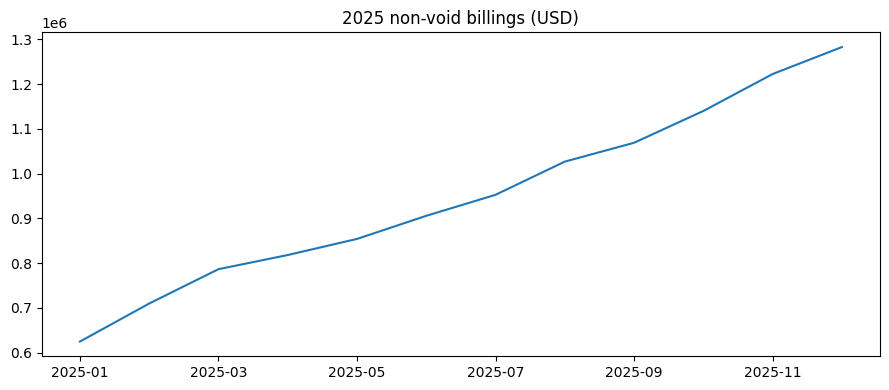

In [75]:
ax = monthly.plot(kind='line', figsize=(9,4), title='2025 non-void billings (USD)')
ax.set_xlabel('')
plt.tight_layout()
plt.savefig(ROOT / 'images/monthly_billings.png', dpi=140)
plt.show()
plt.close()

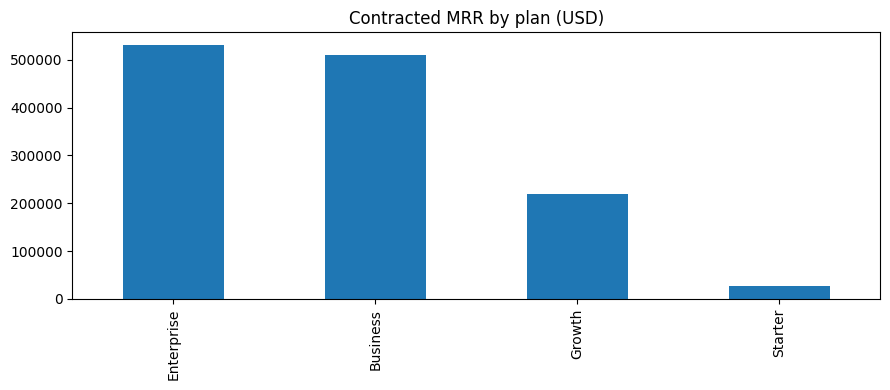

In [76]:
ax = plan.mrr.plot(kind='bar', figsize=(9,4), title='Contracted MRR by plan (USD)')
ax.set_xlabel('')
plt.tight_layout()
plt.savefig(ROOT / 'images/plan_mrr.png', dpi=140)
plt.show()
plt.close()

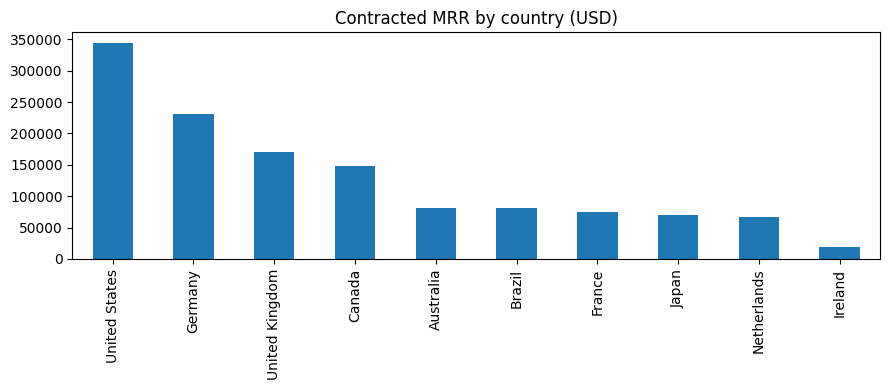

In [77]:
ax = country.mrr.plot(kind='bar', figsize=(9,4), title='Contracted MRR by country (USD)')
ax.set_xlabel('')
plt.tight_layout()
plt.savefig(ROOT / 'images/country_mrr.png', dpi=140)
plt.show()
plt.close()

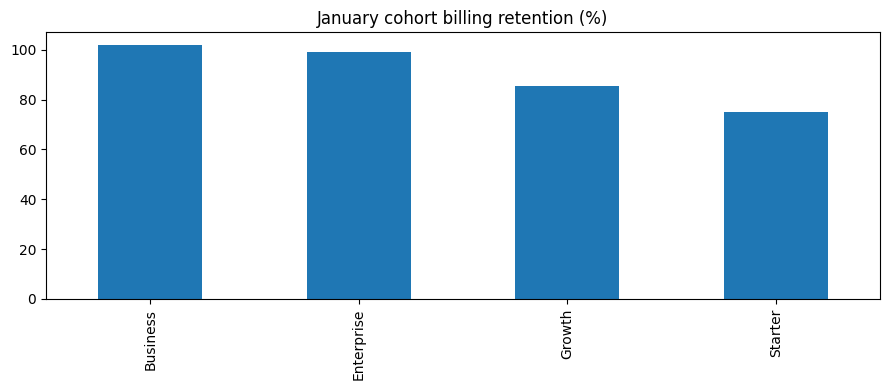

In [78]:
ax = retention.retention_pct.plot(kind='bar', figsize=(9,4), title='January cohort billing retention (%)')
ax.set_xlabel('')
plt.tight_layout()
plt.savefig(ROOT / 'images/cohort_retention.png', dpi=140)
plt.show()
plt.close()

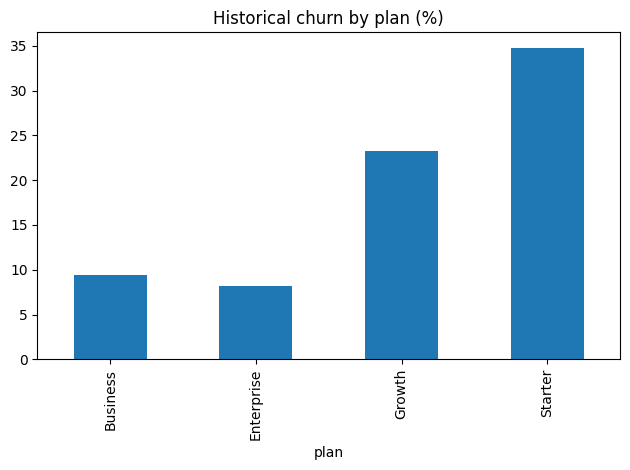

In [79]:
x.groupby('plan').churned.mean().mul(100).plot.bar(title='Historical churn by plan (%)')
plt.tight_layout()
plt.show()

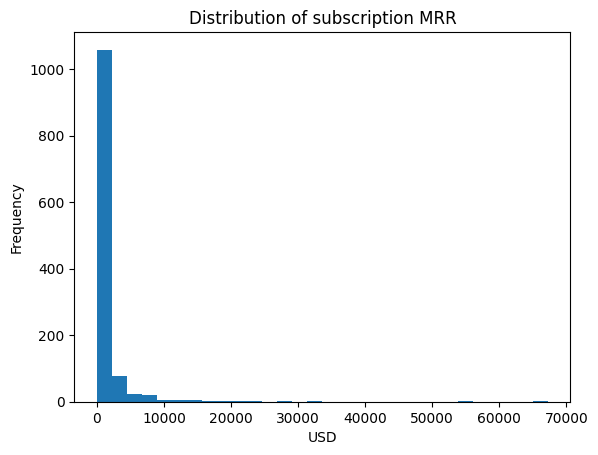

In [80]:
numeric.mrr.plot.hist(bins=30, title='Distribution of subscription MRR')
plt.xlabel('USD')
plt.show()

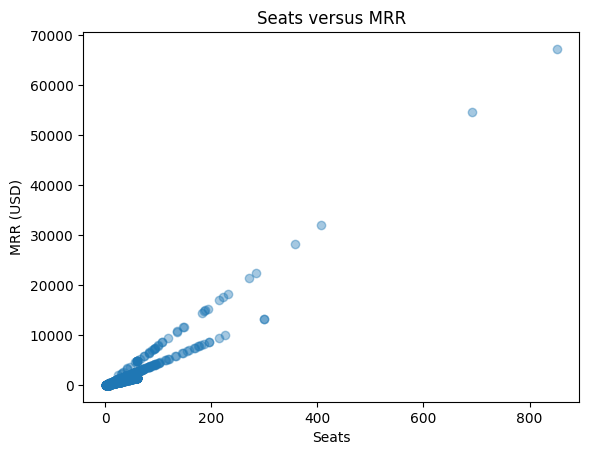

In [81]:
plt.scatter(numeric.seats, numeric.mrr, alpha=.4)
plt.xlabel('Seats')
plt.ylabel('MRR (USD)')
plt.title('Seats versus MRR')
plt.show()

## 12. Machine learning: exploratory historical churn classification
Target: churned versus all other statuses. One row per account. Use only account profile fields (country, industry, employee count); exclude status, end date, invoices, support outcomes, current plan and current MRR because their timing relative to churn is unknown. Profile fields may also have changed; this is a retrospective association exercise, not a validated future churn predictor. Random stratified split is appropriate for this demonstration only.

In [82]:
features = ['country','industry','employee_count']
X = x[features].copy()
y = x['churned'].copy()
display(y.value_counts())

churned
0    907
1    293
Name: count, dtype: int64

### 12.1 Split training and testing data

In [83]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('Training:', X_train.shape)
print('Testing:', X_test.shape)

Training: (960, 3)
Testing: (240, 3)


### 12.2 Preprocess features
Median for numeric missing values, most frequent category for categorical missing values, one-hot encoding and standardisation. Fit only inside training pipelines.

In [84]:
numeric_pipe = Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
category_pipe = Pipeline([('impute', SimpleImputer(strategy='most_frequent')), ('encode', OneHotEncoder(handle_unknown='ignore'))])
preprocess = ColumnTransformer([('numeric', numeric_pipe, ['employee_count']), ('category', category_pipe, ['country','industry'])])

### Train baseline

In [85]:
baseline = Pipeline([("preprocess", preprocess), ("model", DummyClassifier(strategy="prior"))])
baseline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('category', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transfor

### Test baseline

In [86]:
baseline_pred = baseline.predict(X_test)
baseline_prob = baseline.predict_proba(X_test)[:, 1]

### Train logistic

In [87]:
logistic = Pipeline([("preprocess", preprocess), ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))])
logistic.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('category', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transfor

### Test logistic

In [88]:
logistic_pred = logistic.predict(X_test)
logistic_prob = logistic.predict_proba(X_test)[:, 1]

### Train forest

In [89]:
forest = Pipeline([("preprocess", preprocess), ("model", RandomForestClassifier(n_estimators=150, max_depth=5, min_samples_leaf=10, class_weight="balanced", random_state=42))])
forest.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('category', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transfor

### Test forest

In [90]:
forest_pred = forest.predict(X_test)
forest_prob = forest.predict_proba(X_test)[:, 1]

### 12.3 Compare models
Accuracy alone can be misleading for imbalanced churn labels. Recall measures detected churners, precision measures correct churn flags, F1 balances both, ROC-AUC measures ranking discrimination. No tuning or production model selection is claimed from this test set.

In [91]:
results = []
for name, pred, prob in [('Baseline',baseline_pred,baseline_prob),('Logistic regression',logistic_pred,logistic_prob),('Random forest',forest_pred,forest_prob)]:
    results.append({'model':name,'accuracy':accuracy_score(y_test,pred),'precision':precision_score(y_test,pred,zero_division=0),'recall':recall_score(y_test,pred),'f1':f1_score(y_test,pred),'roc_auc':roc_auc_score(y_test,prob)})
metrics = pd.DataFrame(results).set_index('model')
display(metrics.round(3))

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Baseline,0.754,0.000,0.000,0.000,0.500
Logistic regression,0.533,0.288,0.610,0.391,0.556
Random forest,0.633,0.344,0.542,0.421,0.642


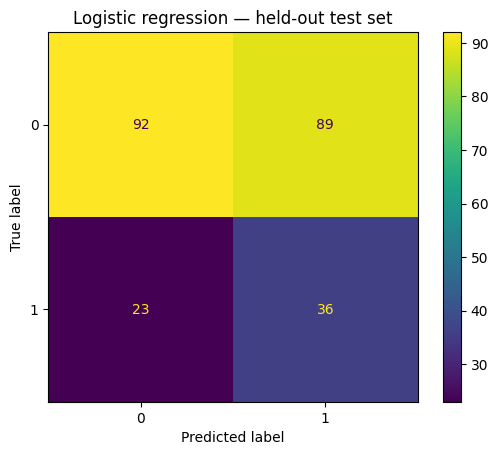

In [92]:
ConfusionMatrixDisplay.from_predictions(y_test, logistic_pred)
plt.title('Logistic regression — held-out test set')
plt.show()

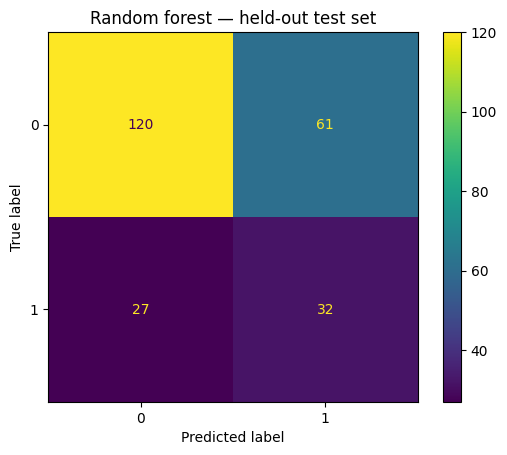

In [93]:
ConfusionMatrixDisplay.from_predictions(y_test, forest_pred)
plt.title('Random forest — held-out test set')
plt.show()

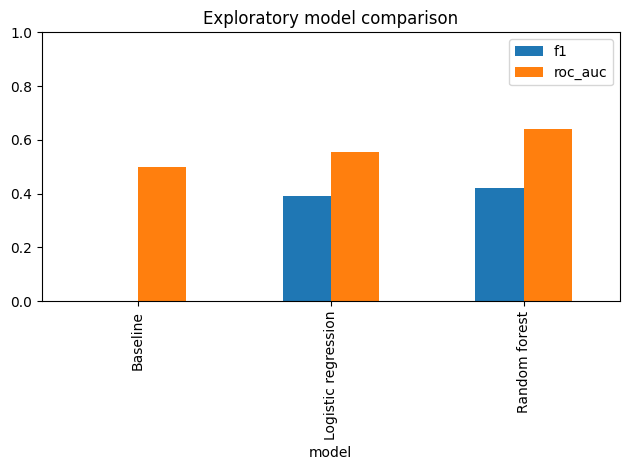

In [94]:
metrics[['f1','roc_auc']].plot.bar(title='Exploratory model comparison', ylim=(0,1))
plt.tight_layout()
plt.show()

In [95]:
print('Highest observed test ROC-AUC:', metrics.roc_auc.idxmax())
print('ROC-AUC:', round(metrics.roc_auc.max(),3))
print('This comparison is exploratory; future prediction requires timestamped features and temporal validation.')

Highest observed test ROC-AUC: Random forest
ROC-AUC: 0.642
This comparison is exploratory; future prediction requires timestamped features and temporal validation.


## 13. Export results and synchronise repository
Existing SQL and Power BI KPI definitions remain unchanged. Model metrics are a separate analytical extension.

In [96]:
for name, df in [('account_summary', x.drop(columns=['company_name'])), ('plan_summary', plan), ('country_summary', country), ('cohort_retention', retention), ('support_summary', support), ('monthly_billings', monthly.to_frame('billings'))]:
    df.to_csv(ROOT / 'data/processed' / f'{name}.csv')

In [97]:
pd.Series(kpi, name='value').to_csv(ROOT / 'data/processed/kpis.csv')

In [98]:
metrics.to_csv(ROOT / 'data/processed/model_metrics.csv')

## 14. Business inferences
Prioritise high-value plan retention; investigate Starter churn and billing collection; evaluate country results with sample sizes. Support ratings exclude nonresponses. Model results are exploratory and must not be used to make customer decisions without prospective validation. See reports/analytical_findings.md for quantified findings.